# TT-29 — TF-IDF
## Tự động phân loại ticket hỗ trợ khách hàng về đúng bộ phận




## 0. Import thư viện và hàm dùng chung

In [1]:
import time
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.dummy import DummyClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay)

RANDOM_STATE = 42
plt.rcParams['figure.figsize'] = (9, 5)


def tai_20newsgroups(bo_remove: bool):
    """bo_remove=True -> remove headers/footers/quotes (bản SẠCH, dùng chính thức)."""
    remove = ('headers', 'footers', 'quotes') if bo_remove else ()
    train = fetch_20newsgroups(subset='train', remove=remove, random_state=RANDOM_STATE)
    test = fetch_20newsgroups(subset='test', remove=remove, random_state=RANDOM_STATE)
    return train, test


def danh_gia(y_true, y_pred):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, average='macro'),
    }


## Bước 1 — Chứng minh rò rỉ do headers/footers/quotes



In [2]:
def do_nhanh_accuracy(train, test):
    """Pipeline tối giản chỉ để SO SÁNH rò rỉ — không phải pipeline sản phẩm."""
    pipe = make_pipeline(TfidfVectorizer(), LinearSVC(random_state=RANDOM_STATE))
    pipe.fit(train.data, train.target)
    return accuracy_score(test.target, pipe.predict(test.data))

train_co_rori, test_co_rori = tai_20newsgroups(bo_remove=False)
train_sach, test_sach = tai_20newsgroups(bo_remove=True)

acc_co_rori = do_nhanh_accuracy(train_co_rori, test_co_rori)
acc_sach = do_nhanh_accuracy(train_sach, test_sach)

bang_leakage = pd.DataFrame({
    'Phiên bản dữ liệu': ['CÓ headers/footers/quotes (rò rỉ)', 'ĐÃ remove (dùng chính thức)'],
    'Accuracy': [acc_co_rori, acc_sach],
})
print(bang_leakage)
print(f"\nChênh lệch: {acc_co_rori - acc_sach:+.3f}")
print("→ Accuracy cao bất thường ở bản CÓ header chứng tỏ model học dòng")
print("  'Newsgroups: ...' thay vì nội dung — đây chính là đáp án bị lộ ra đầu vào.")
print("→ Mọi bước từ đây dùng train_sach / test_sach.")


                   Phiên bản dữ liệu  Accuracy
0  CÓ headers/footers/quotes (rò rỉ)  0.853160
1        ĐÃ remove (dùng chính thức)  0.691981

Chênh lệch: +0.161
→ Accuracy cao bất thường ở bản CÓ header chứng tỏ model học dòng
  'Newsgroups: ...' thay vì nội dung — đây chính là đáp án bị lộ ra đầu vào.
→ Mọi bước từ đây dùng train_sach / test_sach.


## Bước 2 — EDA: số văn bản mỗi lớp, độ dài văn bản, từ phổ biến nhất

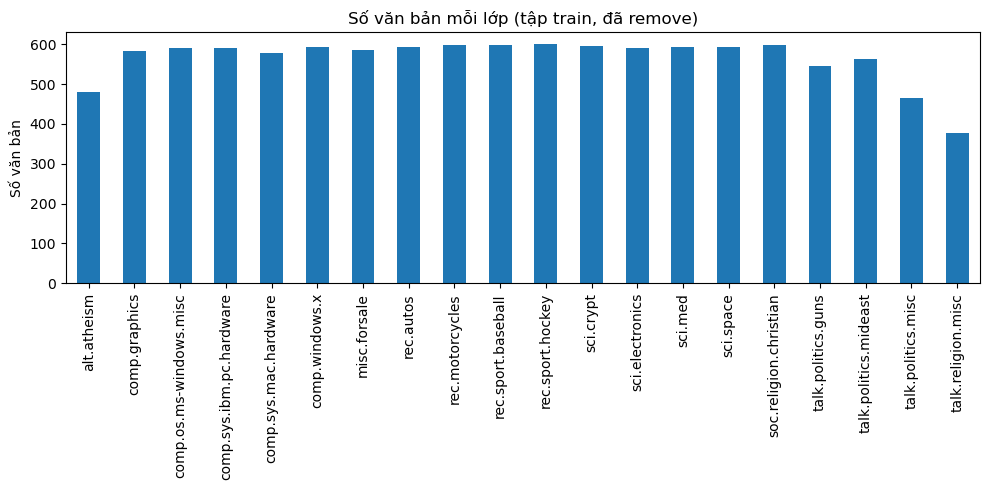

Số lớp: 20 | Mất cân bằng: min=377, max=600


In [3]:
# Số văn bản mỗi lớp
so_luong_lop = pd.Series(train_sach.target).value_counts().sort_index()
so_luong_lop.index = [train_sach.target_names[i] for i in so_luong_lop.index]

fig, ax = plt.subplots(figsize=(10, 5))
so_luong_lop.plot(kind='bar', ax=ax)
ax.set_title('Số văn bản mỗi lớp (tập train, đã remove)')
ax.set_ylabel('Số văn bản')
plt.tight_layout()
plt.show()
print(f"Số lớp: {len(so_luong_lop)} | Mất cân bằng: min={so_luong_lop.min()}, max={so_luong_lop.max()}")


count    11314.000000
mean       185.827382
std        523.971647
min          0.000000
25%         40.000000
50%         83.000000
75%        167.000000
max      11765.000000
dtype: float64


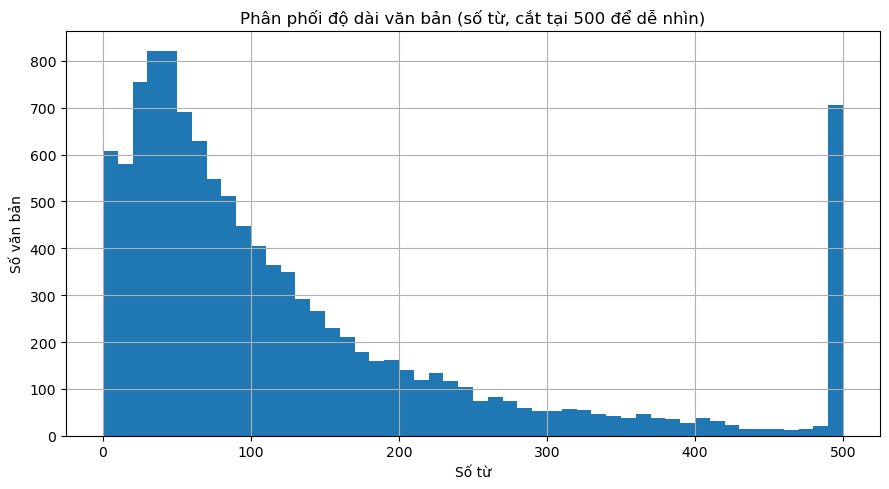

In [4]:
# Độ dài văn bản (số từ)
do_dai_tu = pd.Series([len(doc.split()) for doc in train_sach.data])
print(do_dai_tu.describe())

fig, ax = plt.subplots()
do_dai_tu.clip(upper=500).hist(bins=50, ax=ax)
ax.set_title('Phân phối độ dài văn bản (số từ, cắt tại 500 để dễ nhìn)')
ax.set_xlabel('Số từ'); ax.set_ylabel('Số văn bản')
plt.tight_layout()
plt.show()


In [5]:
# Từ phổ biến nhất (loại stopword tiếng Anh)
dem_tu = CountVectorizer(stop_words='english', max_features=20)
dem_tu.fit(train_sach.data)
print("20 từ phổ biến nhất (đã loại stopword):")
print(list(dem_tu.get_feature_names_out()))


20 từ phổ biến nhất (đã loại stopword):
['ax', 'does', 'don', 'edu', 'god', 'good', 'just', 'know', 'like', 'make', 'max', 'new', 'people', 'say', 'think', 'time', 'use', 'used', 've', 'way']


## Bước 3 — Baseline: DummyClassifier + Naive Bayes

In [6]:
dummy = DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE)
dummy.fit(train_sach.data, train_sach.target)
acc_dummy = accuracy_score(test_sach.target, dummy.predict(test_sach.data))

pipe_nb = make_pipeline(TfidfVectorizer(min_df=3, max_df=0.8), MultinomialNB())
pipe_nb.fit(train_sach.data, train_sach.target)
acc_nb = accuracy_score(test_sach.target, pipe_nb.predict(test_sach.data))

print(f"DummyClassifier (most_frequent) : accuracy = {acc_dummy:.3f}  <- sàn tối thiểu phải vượt qua")
print(f"Naive Bayes (TF-IDF)             : accuracy = {acc_nb:.3f}")


DummyClassifier (most_frequent) : accuracy = 0.053  <- sàn tối thiểu phải vượt qua
Naive Bayes (TF-IDF)             : accuracy = 0.633


## Bước 4 — TF-IDF + LinearSVC

`LinearSVC` không có `predict_proba`, nên bọc `CalibratedClassifierCV` để lấy
xác suất

In [7]:
pipe_chinh = make_pipeline(
    TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=3, max_df=0.8,
                    sublinear_tf=True, max_features=50000),
    CalibratedClassifierCV(LinearSVC(C=1.0, random_state=RANDOM_STATE), cv=3),
)
pipe_chinh.fit(train_sach.data, train_sach.target)

du_doan_chinh = pipe_chinh.predict(test_sach.data)
ket_qua_chinh = danh_gia(test_sach.target, du_doan_chinh)
print(f"TF-IDF + LinearSVC (calibrated): accuracy = {ket_qua_chinh['accuracy']:.3f} "
      f"| macro-F1 = {ket_qua_chinh['macro_f1']:.3f}")
print("Mức tham chiếu README (đã remove headers): ~0.69-0.73")


TF-IDF + LinearSVC (calibrated): accuracy = 0.689 | macro-F1 = 0.676
Mức tham chiếu README (đã remove headers): ~0.69-0.73


## Bước 5 — Khảo sát tham số vectorizer

Dò `ngram_range`, `min_df`, `sublinear_tf` bằng **cross-validation trên train**
(không chạm vào test) để tránh rò rỉ thông tin test vào lúc chọn tham số.

In [8]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
ket_qua_khao_sat = []

for ngram_range in [(1, 1), (1, 2)]:
    for min_df in [1, 3, 5]:
        for sublinear_tf in [True, False]:
            vect = TfidfVectorizer(ngram_range=ngram_range, min_df=min_df,
                                   max_df=0.8, sublinear_tf=sublinear_tf, max_features=50000)
            X_vect = vect.fit_transform(train_sach.data)
            diem_cv = cross_val_score(LinearSVC(random_state=RANDOM_STATE), X_vect,
                                       train_sach.target, cv=cv, scoring='accuracy')
            ket_qua_khao_sat.append({
                'ngram_range': ngram_range, 'min_df': min_df, 'sublinear_tf': sublinear_tf,
                'so_dac_trung': X_vect.shape[1], 'accuracy_cv': diem_cv.mean(),
            })

bang_khao_sat = pd.DataFrame(ket_qua_khao_sat).sort_values('accuracy_cv', ascending=False)
print(bang_khao_sat.to_string(index=False))

tham_so_tot_nhat = bang_khao_sat.iloc[0][['ngram_range', 'min_df', 'sublinear_tf']].to_dict()
print("\nTham số tốt nhất theo CV:", tham_so_tot_nhat)


ngram_range  min_df  sublinear_tf  so_dac_trung  accuracy_cv
     (1, 1)       1          True         50000     0.754198
     (1, 1)       1         False         50000     0.751370
     (1, 1)       3          True         27052     0.749337
     (1, 1)       3         False         27052     0.747127
     (1, 1)       5          True         18100     0.744033
     (1, 2)       3          True         50000     0.742973
     (1, 2)       1          True         50000     0.741205
     (1, 2)       5          True         50000     0.741028
     (1, 2)       3         False         50000     0.740233
     (1, 1)       5         False         18100     0.739526
     (1, 2)       1         False         50000     0.739084
     (1, 2)       5         False         50000     0.738200

Tham số tốt nhất theo CV: {'ngram_range': (1, 1), 'min_df': 1, 'sublinear_tf': True}


## Bước 6 — So sánh 3 bộ phân loại trên CÙNG TF-IDF

Dùng tham số tốt nhất tìm được ở Bước 5, giữ cố định vectorizer, chỉ đổi
classifier để so sánh công bằng.

In [9]:
vect_tot_nhat = TfidfVectorizer(ngram_range=tham_so_tot_nhat['ngram_range'],
                                min_df=tham_so_tot_nhat['min_df'], max_df=0.8,
                                sublinear_tf=tham_so_tot_nhat['sublinear_tf'], max_features=50000)
X_train_vect = vect_tot_nhat.fit_transform(train_sach.data)
X_test_vect = vect_tot_nhat.transform(test_sach.data)

cac_mo_hinh = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'LinearSVC': LinearSVC(random_state=RANDOM_STATE),
}

ket_qua_so_sanh = []
for ten, mh in cac_mo_hinh.items():
    mh.fit(X_train_vect, train_sach.target)
    diem = danh_gia(test_sach.target, mh.predict(X_test_vect))
    ket_qua_so_sanh.append({'Mô hình': ten, 'Accuracy': diem['accuracy'], 'Macro-F1': diem['macro_f1']})

bang_so_sanh_mo_hinh = pd.DataFrame(ket_qua_so_sanh)
print(bang_so_sanh_mo_hinh)


               Mô hình  Accuracy  Macro-F1
0          Naive Bayes  0.623739  0.597836
1  Logistic Regression  0.683617  0.667987
2            LinearSVC  0.695964  0.684775


## Bước 7 — Top 15 từ trọng số cao nhất mỗi lớp



In [10]:
mo_hinh_dien_giai = LinearSVC(random_state=RANDOM_STATE)
mo_hinh_dien_giai.fit(X_train_vect, train_sach.target)

ten_dac_trung = vect_tot_nhat.get_feature_names_out()
top_tu_moi_lop = {}
for idx_lop, ten_lop in enumerate(train_sach.target_names):
    trong_so = mo_hinh_dien_giai.coef_[idx_lop]
    top15_idx = np.argsort(trong_so)[-15:][::-1]
    top_tu_moi_lop[ten_lop] = ten_dac_trung[top15_idx].tolist()
    print(f"{ten_lop:28s}: {', '.join(top_tu_moi_lop[ten_lop])}")


alt.atheism                 : atheism, motto, atheists, bobby, religion, islam, islamic, nanci, deletion, cruel, punishment, bsa, atheist, loans, species
comp.graphics               : graphics, 3d, image, images, 68070, animation, pov, tiff, cview, 3do, polygons, viewer, polygon, sphere, phigs
comp.os.ms-windows.misc     : windows, cica, win3, risc, mfc, ini, file, w4wg, smartdrv, nt, download, microsoft, os2, characters, winqvt
comp.sys.ibm.pc.hardware    : vlb, ide, bios, gateway, cmos, f550iw, os, t560i, fastmicro, controller, 486, adaptec, pc, qemm, gw2000
comp.sys.mac.hardware       : mac, apple, powerbook, quadra, se, lc, centris, adb, duo, nubus, c650, iisi, lciii, simms, vram
comp.windows.x              : motif, server, widget, x11r5, xterm, window, mit, widgets, x11, clients, xlib, openwindows, terminals, binaries, pixmap
misc.forsale                : sale, shipping, sell, offer, 2190, interested, condition, buyer, forsale, asking, summer, tracy, includes, new, pay
rec.autos  

## Bước 8 — Ma trận nhầm lẫn: nhóm chủ đề nào hay nhầm nhau?

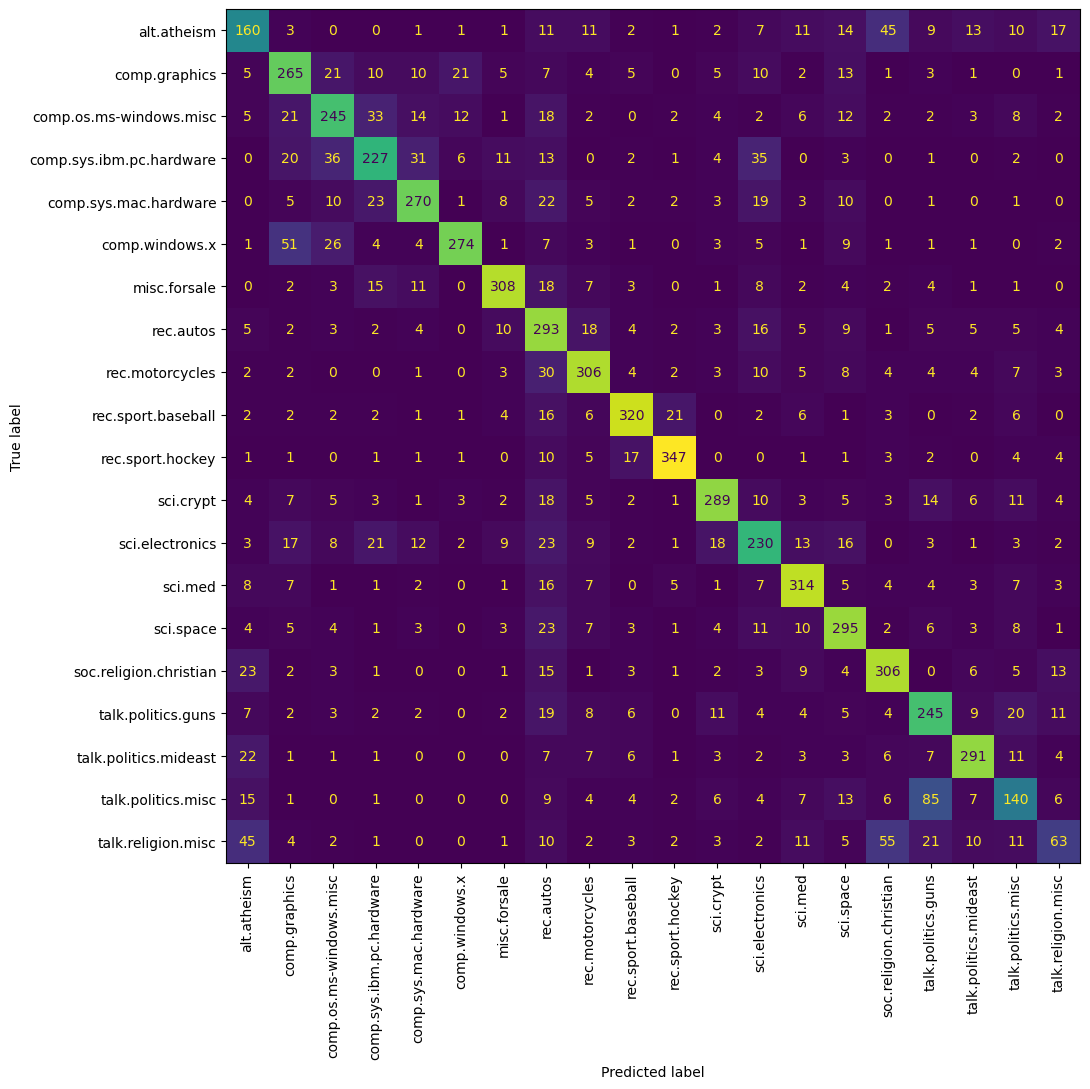

Thật 'talk.politics.misc' bị đoán nhầm thành 'talk.politics.guns': 85 lần
Thật 'talk.religion.misc' bị đoán nhầm thành 'soc.religion.christian': 55 lần
Thật 'comp.windows.x' bị đoán nhầm thành 'comp.graphics': 51 lần
Thật 'alt.atheism' bị đoán nhầm thành 'soc.religion.christian': 45 lần
Thật 'talk.religion.misc' bị đoán nhầm thành 'alt.atheism': 45 lần


In [11]:
cm = confusion_matrix(test_sach.target, du_doan_chinh)

fig, ax = plt.subplots(figsize=(11, 11))
ConfusionMatrixDisplay(cm, display_labels=test_sach.target_names).plot(
    ax=ax, xticks_rotation=90, colorbar=False)
plt.tight_layout()
plt.show()

# Top 5 cặp lớp hay bị nhầm nhất (bỏ đường chéo, bỏ cặp không hề bị nhầm)
cm_khong_duong_cheo = cm.copy()
np.fill_diagonal(cm_khong_duong_cheo, 0)
cap_nham_lan = [(i, j, cm_khong_duong_cheo[i, j])
               for i in range(cm.shape[0]) for j in range(cm.shape[1])
               if i != j and cm_khong_duong_cheo[i, j] > 0]
cap_nham_lan.sort(key=lambda bo: bo[2], reverse=True)

if not cap_nham_lan:
    print("Không có cặp lớp nào bị nhầm — mô hình phân loại đúng tuyệt đối trên test.")
for i, j, so_lan in cap_nham_lan[:5]:
    print(f"Thật '{test_sach.target_names[i]}' bị đoán nhầm thành "
          f"'{test_sach.target_names[j]}': {so_lan} lần")


## Bước 9 —  Cơ chế ngưỡng tin cậy

Nếu xác suất lớn nhất < 0.6 → chuyển cho người xử lý thay vì tự động gán bộ
phận, để tránh ticket bị chuyển sai làm vỡ SLA.

In [12]:
xac_suat = pipe_chinh.predict_proba(test_sach.data)
du_doan_tu_proba = np.argmax(xac_suat, axis=1)
do_tin_cay = xac_suat.max(axis=1)

NGUONG_TIN_CAY = 0.6
mat_na_tu_dong = do_tin_cay >= NGUONG_TIN_CAY

ty_le_tu_dong = mat_na_tu_dong.mean()
acc_phan_tu_dong = accuracy_score(test_sach.target[mat_na_tu_dong],
                                   du_doan_tu_proba[mat_na_tu_dong])
acc_khong_nguong = accuracy_score(test_sach.target, du_doan_tu_proba)

bang_nguong = pd.DataFrame({
    'Chỉ số': ['% ticket tự động xử lý', 'Accuracy của phần tự động',
              '% ticket cần người xử lý', 'Accuracy nếu xử lý 100% tự động (không ngưỡng)'],
    'Giá trị': [f"{ty_le_tu_dong:.1%}", f"{acc_phan_tu_dong:.3f}",
               f"{1 - ty_le_tu_dong:.1%}", f"{acc_khong_nguong:.3f}"],
})
print(bang_nguong.to_string(index=False))
print("\n→ So accuracy phần tự động với accuracy không ngưỡng: ngưỡng có thực sự lọc ra")
print("  được các ca dễ sai hay không.")


                                        Chỉ số Giá trị
                        % ticket tự động xử lý   49.8%
                     Accuracy của phần tự động   0.916
                      % ticket cần người xử lý   50.2%
Accuracy nếu xử lý 100% tự động (không ngưỡng)   0.689

→ So accuracy phần tự động với accuracy không ngưỡng: ngưỡng có thực sự lọc ra
  được các ca dễ sai hay không.


## Bước 10 — Đo thời gian train và dự đoán (yêu cầu dự đoán < 5 ms/ticket)

In [13]:
t0 = time.time()
pipe_chinh.fit(train_sach.data, train_sach.target)
thoi_gian_train_giay = time.time() - t0

mot_ticket = [test_sach.data[0]]
t0 = time.time()
pipe_chinh.predict(mot_ticket)
thoi_gian_du_doan_ms = (time.time() - t0) * 1000

print(f"Thời gian train toàn bộ : {thoi_gian_train_giay:.1f} giây")
print(f"Thời gian dự đoán 1 ticket: {thoi_gian_du_doan_ms:.2f} ms "
      f"({'ĐẠT' if thoi_gian_du_doan_ms < 5 else 'CHƯA ĐẠT'} yêu cầu < 5 ms)")


Thời gian train toàn bộ : 31.6 giây
Thời gian dự đoán 1 ticket: 27.41 ms (CHƯA ĐẠT yêu cầu < 5 ms)


## Bước 11 — Phân tích 10 ca dự đoán sai

In [14]:
chi_so_sai = np.where(du_doan_chinh != test_sach.target)[0]
rng = np.random.default_rng(RANDOM_STATE)
mau_sai = rng.choice(chi_so_sai, size=min(10, len(chi_so_sai)), replace=False)

print(f"Tổng số ca sai trên tập test: {len(chi_so_sai)}/{len(test_sach.target)}\n")
for i in mau_sai:
    print(f"--- Ticket #{i} ---")
    print(f"Thật: {test_sach.target_names[test_sach.target[i]]:28s} | "
          f"Đoán: {test_sach.target_names[du_doan_chinh[i]]}")
    print(test_sach.data[i][:200].replace(chr(10), ' ') + " ...")
    print()


Tổng số ca sai trên tập test: 2344/7532

--- Ticket #622 ---
Thật: talk.politics.guns           | Đoán: sci.electronics
  Look, I don't want to bore everybody here with the physics of woodstoves, but they're not anything like your Caloric gas range.  It takes about three hours for a woodstove to get hot enough to cook  ...

--- Ticket #5740 ---
Thật: sci.space                    | Đoán: rec.sport.baseball
I'm afraid I was not able to find the GIFs... is the list  updated weekly, perhaps, or am I just missing something? ...

--- Ticket #642 ---
Thật: rec.sport.baseball           | Đoán: sci.med
  If it encouraged the runner to stretch his lead, it would probably also result ina greater number of pickoffs. I think it would be a workable rule, but it would probably be best to experiment in ano ...

--- Ticket #4865 ---
Thật: rec.sport.baseball           | Đoán: talk.politics.misc
 Nah, let's reserve rec.sports.idiots for people who POST obvious flamebait, like yourself.  If someone posts 

## Tổng kết

- **Hạn chế cố hữu của TF-IDF**: chỉ đếm từ, không hiểu nghĩa — "tuyệt vời" và
  "hay" là 2 chiều hoàn toàn khác nhau với TF-IDF dù con người thấy chúng gần
  nghĩa. Đây là lý do các cặp lớp chủ đề gần nhau về ngữ nghĩa (ví dụ các
  nhóm `comp.*` hoặc `talk.politics.*`) thường bị nhầm nhiều hơn (xem Bước 8).
- **Mở rộng chưa làm trong notebook này** (đúng tinh thần README mục 8 —
  đây là phần mở rộng, không bắt buộc): SVD/LSA để giảm chiều ma trận TF-IDF;
  so sánh với PhoBERT; học trực tuyến bằng `SGDClassifier.partial_fit()`. Nếu
  làm thêm, nên tách thành notebook/cell riêng để không làm phình bản chính.
- **Trước khi nộp bài**: copy các số liệu in ra ở Bước 1, 4, 5, 6, 9, 10 vào
  README thật của bạn (bảng rò rỉ, bảng khảo sát tham số, bảng so sánh model,
  bảng ngưỡng tin cậy) — notebook này không tự ghi đè README đề bài.
- **Git workflow**: nên commit theo từng bước có ý nghĩa (ví dụ: "Bước 1-3:
  EDA + baseline", "Bước 4-6: pipeline chính + khảo sát tham số", "Bước 7-11:
  diễn giải + ngưỡng tin cậy + báo cáo lỗi") thay vì 1 commit lớn duy nhất, và
  không commit theo thư mục cache/model lớn không cần thiết nếu không bắt buộc
  phải nộp qua Git.


In [15]:
import glob, os, subprocess, sys
import joblib

for thu_muc in ["models", "reports", "src"]:
    os.makedirs(thu_muc, exist_ok=True)

# Dọn file rác lỡ ghi nhầm vào thư mục gốc ở các lần chạy trước (nếu có)
for ten_file_rac in ["tfidf_pipeline.joblib", "leakage_comparison.png", "top_tu_moi_lop.png",
                     "confusion_matrix.png", "nguong_tin_cay.png", "train.py",
                     "preprocess.py", "requirements.txt"]:
    if os.path.exists(ten_file_rac):
        os.remove(ten_file_rac)

# 1) Model
joblib.dump(pipe_chinh, "models/tfidf_pipeline.joblib")

# 2) reports/leakage_comparison.png
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(bang_leakage['Phiên bản dữ liệu'], bang_leakage['Accuracy'], color=['crimson', 'seagreen'])
ax.set_ylabel('Accuracy')
ax.set_title('Rò rỉ nhãn qua headers/footers/quotes')
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
fig.savefig("reports/leakage_comparison.png", dpi=120)
plt.close(fig)

# 3) reports/top_tu_moi_lop.png
fig, ax = plt.subplots(figsize=(12, 0.45 * len(top_tu_moi_lop) + 1))
ax.axis('off')
du_lieu_bang = [[ten_lop, ', '.join(tu[:8])] for ten_lop, tu in top_tu_moi_lop.items()]
bang_ve = ax.table(cellText=du_lieu_bang, colLabels=['Lớp', 'Top 8/15 từ trọng số cao nhất'],
                   loc='center', cellLoc='left', colWidths=[0.25, 0.75])
bang_ve.auto_set_font_size(False)
bang_ve.set_fontsize(8)
ax.set_title('Top từ đặc trưng mỗi lớp (LinearSVC coef_)')
fig.tight_layout()
fig.savefig("reports/top_tu_moi_lop.png", dpi=120, bbox_inches='tight')
plt.close(fig)

# 4) reports/confusion_matrix.png
fig, ax = plt.subplots(figsize=(11, 11))
ConfusionMatrixDisplay(cm, display_labels=test_sach.target_names).plot(
    ax=ax, xticks_rotation=90, colorbar=False)
fig.tight_layout()
fig.savefig("reports/confusion_matrix.png", dpi=120)
plt.close(fig)

# 5) reports/nguong_tin_cay.png
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(do_tin_cay[mat_na_tu_dong], bins=30, alpha=0.7, label='Tự động xử lý (>= ngưỡng)', color='seagreen')
ax.hist(do_tin_cay[~mat_na_tu_dong], bins=30, alpha=0.7, label='Chuyển người (< ngưỡng)', color='crimson')
ax.axvline(NGUONG_TIN_CAY, color='black', linestyle='--', label=f'Ngưỡng = {NGUONG_TIN_CAY}')
ax.set_xlabel('Độ tin cậy (max proba)')
ax.set_ylabel('Số ticket')
ax.set_title('Phân phối độ tin cậy & cơ chế ngưỡng')
ax.legend()
fig.tight_layout()
fig.savefig("reports/nguong_tin_cay.png", dpi=120)
plt.close(fig)

print("Đã lưu: models/tfidf_pipeline.joblib, reports/leakage_comparison.png, "
      "reports/top_tu_moi_lop.png, reports/confusion_matrix.png, reports/nguong_tin_cay.png")

# 6) src/preprocess.py — module tải + làm sạch dữ liệu, tách riêng để tái dùng
noi_dung_preprocess = '''"""Tải và làm sạch dữ liệu 20 Newsgroups cho bài toán phân loại ticket."""
from sklearn.datasets import fetch_20newsgroups

RANDOM_STATE = 42


def tai_20newsgroups(bo_remove: bool = True):
    """bo_remove=True -> remove headers/footers/quotes (bản SẠCH, dùng chính thức).

    QUAN TRỌNG: bo_remove=False chỉ dùng để minh chứng rò rỉ (xem Bước 1 notebook),
    KHÔNG dùng để train model thật.
    """
    remove = ('headers', 'footers', 'quotes') if bo_remove else ()
    train = fetch_20newsgroups(subset='train', remove=remove, random_state=RANDOM_STATE)
    test = fetch_20newsgroups(subset='test', remove=remove, random_state=RANDOM_STATE)
    return train, test
'''
with open("src/preprocess.py", "w", encoding="utf-8") as f:
    f.write(noi_dung_preprocess)

# 7) src/train.py — xuất toàn bộ notebook thành script (tự nhận diện tên file)
cac_file_ipynb = glob.glob("*.ipynb")
if len(cac_file_ipynb) == 1:
    ten_notebook = cac_file_ipynb[0]
    ket_qua = subprocess.run([sys.executable, "-m", "jupyter", "nbconvert", "--to", "script",
                               ten_notebook, "--output-dir", "src", "--output", "train"])
    duong_dan_txt = os.path.join("src", "train.txt")
    duong_dan_py = os.path.join("src", "train.py")
    if os.path.exists(duong_dan_txt):
        os.replace(duong_dan_txt, duong_dan_py)
    if ket_qua.returncode == 0 and os.path.exists(duong_dan_py):
        print(f"Đã xuất src/train.py từ notebook: {ten_notebook}")
    else:
        print(" nbconvert chạy lỗi hoặc không tạo được src/train.py.")
else:
    print(f"Tìm thấy {len(cac_file_ipynb)} file .ipynb — không tự chọn được. "
          f"Hãy tự chạy: jupyter nbconvert --to script <ten_notebook>.ipynb --output-dir src --output train")

# 8) requirements.txt — chỉ liệt kê thư viện thực sự dùng
thu_vien_da_dung = ["numpy", "pandas", "matplotlib", "scikit-learn", "joblib"]
with open("requirements.txt", "w") as f:
    f.write("\n".join(thu_vien_da_dung) + "\n")

# 9) README.md — tạo MỚI cho thư mục nộp bài (không đụng tới README đề bài gốc),
#    điền số liệu THẬT lấy từ các bước trên.
def df_sang_markdown(df):
    """Tự chuyển DataFrame sang bảng Markdown, không cần gói tabulate."""
    cot = list(df.columns)
    dong_tieu_de = "| " + " | ".join(str(c) for c in cot) + " |"
    dong_gach = "| " + " | ".join("---" for _ in cot) + " |"
    dong_du_lieu = ["| " + " | ".join(str(v) for v in hang) + " |" for hang in df.values]
    return "\n".join([dong_tieu_de, dong_gach] + dong_du_lieu)

bang_khao_sat_top5_md = df_sang_markdown(bang_khao_sat.head(5))
bang_so_sanh_mo_hinh_md = df_sang_markdown(bang_so_sanh_mo_hinh)
bang_nguong_md = df_sang_markdown(bang_nguong)
top_tu_md = "\n".join(f"- **{ten_lop}**: {', '.join(tu[:10])}"
                      for ten_lop, tu in top_tu_moi_lop.items())

readme_noi_dung = f"""# TT-29 — TF-IDF: Phân loại ticket hỗ trợ khách hàng

## 1. Bảng chứng minh rò rỉ (Bước 1)

| Phiên bản dữ liệu | Accuracy |
|---|---|
| CÓ headers/footers/quotes (rò rỉ) | {acc_co_rori:.3f} |
| ĐÃ remove (dùng chính thức) | {acc_sach:.3f} |

Chênh lệch: {acc_co_rori - acc_sach:+.3f}. Toàn bộ các bước sau chỉ dùng bản ĐÃ remove.

## 2. Kết quả mô hình chính (Bước 4)

TF-IDF (ngram (1,2), min_df=3, max_df=0.8, sublinear_tf=True) + LinearSVC
(calibrated): **accuracy = {ket_qua_chinh['accuracy']:.3f}**, **macro-F1 =
{ket_qua_chinh['macro_f1']:.3f}** (mức tham chiếu README: ~0.69-0.73).

## 3. Khảo sát tham số vectorizer (Bước 5, top 5)

{bang_khao_sat_top5_md}

Tham số tốt nhất theo CV: `{tham_so_tot_nhat}`

## 4. So sánh 3 bộ phân loại (Bước 6)

{bang_so_sanh_mo_hinh_md}

## 5. Top từ đặc trưng mỗi lớp (Bước 7)

{top_tu_md}

## 6. Cơ chế ngưỡng tin cậy (Bước 9)

{bang_nguong_md}

## 7. Thời gian xử lý (Bước 10)

- Train toàn bộ: {thoi_gian_train_giay:.1f} giây
- Dự đoán 1 ticket: {thoi_gian_du_doan_ms:.2f} ms
  ({'ĐẠT' if thoi_gian_du_doan_ms < 5 else 'CHƯA ĐẠT'} yêu cầu < 5 ms)

## 8. Hạn chế

TF-IDF chỉ đếm từ, không hiểu nghĩa ("tuyệt vời" ≠ "hay" với TF-IDF) — xem
Bước 8 (ma trận nhầm lẫn) để biết các cặp chủ đề gần nghĩa hay bị nhầm.

## Cấu trúc thư mục

- `notebooks/` — notebook đầy đủ 11 bước
- `src/preprocess.py` — tải & làm sạch dữ liệu
- `src/train.py` — script train đầy đủ (xuất từ notebook)
- `models/tfidf_pipeline.joblib` — pipeline đã train
- `reports/` — leakage_comparison.png, top_tu_moi_lop.png, confusion_matrix.png, nguong_tin_cay.png
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme_noi_dung)

print("Đã lưu: requirements.txt, README.md (điền số liệu thật từ notebook)")


Đã lưu: models/tfidf_pipeline.joblib, reports/leakage_comparison.png, reports/top_tu_moi_lop.png, reports/confusion_matrix.png, reports/nguong_tin_cay.png
Đã xuất src/train.py từ notebook: TT29_TFIDF_Ticket_Classification.ipynb
Đã lưu: requirements.txt, README.md (điền số liệu thật từ notebook)
